### Import Libraries

In [1]:
!pip install -q pytorchvideo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.7/132.7 kB 2.8 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 54.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 5.5 MB/s eta 0:00:00


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import shutil
import copy
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import torch
import math, random
from multiprocessing import Pool
from tqdm.auto import tqdm

# Introduction

In recent years, surveillance cameras are widely deployed in public places, and the general crime rate has been reduced significantly due to these ubiquitous devices. Usually, these cameras provide cues and evidence after crimes are conducted, while they are rarely used to prevent or stop criminal activities in time. It is both time and labor consuming to manually monitor a large amount of video data from surveillance cameras. Therefore, automatically recognizing violent behaviors from video signals becomes essential. This project utilizes the RWF2000 video dataset consisting of 2,000 videos captured by surveillance cameras in real-world scenes for violence detection and proposes several models for Object Detection and Object Tracking.

# Problem Definition

We propose a solution for Violence Detection in public places using surveillance footage where the system continuously analyzes video streams to identify people, track their movements, and recognize potentially violent activities such as physical fights.

The proposed system consists of three primary tasks:

1. **Object Detection**: A pretrained object detection model is used to detect people in each frame of the surveillance video. The system identifies the location of each person using bounding boxes.

2. **Object Tracking**: Once people are detected, an object-tracking algorithm assigns a unique ID to each individual and maintains that identity across consecutive frames. This enables the system to monitor the movement and interactions of individuals over time.

3. **Action Recognition**: The system continuously analyzes the movements and interactions of tracked individuals to recognize actions associated with violence, particularly fighting incidents. When potentially violent activity is detected, the system can generate an alert for further investigation or intervention.

# Data Understanding and Exploration

In [3]:
DATASET_PATH = "/kaggle/input/datasets/vulamnguyen/rwf2000/RWF-2000"
TRAIN_DATA_PATH = os.path.join(DATASET_PATH, "train")
VAL_DATA_PATH = os.path.join(DATASET_PATH, "val")
TRAIN_FIGHT_PATH = os.path.join(TRAIN_DATA_PATH, "Fight")
TRAIN_NONFIGHT_PATH = os.path.join(TRAIN_DATA_PATH, "NonFight")
VAL_FIGHT_PATH = os.path.join(VAL_DATA_PATH, "Fight")
VAL_NONFIGHT_PATH = os.path.join(VAL_DATA_PATH, "NonFight")

<h3>Classes in the data</h3>

In [4]:
classes = os.listdir(TRAIN_DATA_PATH)
n_classes = len(classes)
print(f"Classes: {classes}")

Classes: ['Fight', 'NonFight']


<h3>Size of the dataset</h3>

In [5]:
n_train_fight = len(os.listdir(TRAIN_FIGHT_PATH))
n_train_nonfight = len(os.listdir(TRAIN_NONFIGHT_PATH))
n_val_fight = len(os.listdir(VAL_FIGHT_PATH))
n_val_nonfight = len(os.listdir(VAL_NONFIGHT_PATH))

data_dist = pd.DataFrame({"Fight": [n_train_fight, n_val_fight], "NonFight": [n_train_nonfight, n_val_nonfight]}, index=["Train", "Val"])
print("Total: ", n_train_fight+n_train_nonfight+n_val_fight+n_val_nonfight)
data_dist

Total:  2000


,Fight,NonFight
Train,800,800
Val,200,200


Now let's see a fight and a nonfight video from the dataset

**Fight**

In [6]:
from IPython.display import Video
!ffmpeg -y -i /kaggle/input/datasets/vulamnguyen/rwf2000/RWF-2000/train/Fight/-1l5631l3fg_0.avi -vcodec libx264 fight0.mp4
display(Video("fight0.mp4", embed=True))

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

**Non Fight**

In [7]:
!ffmpeg -y -i /kaggle/input/datasets/vulamnguyen/rwf2000/RWF-2000/train/NonFight/-1l5631l3fg_0.avi -vcodec libx264 fight1.mp4
display(Video("fight1.mp4", embed=True))

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

## Class Distribution

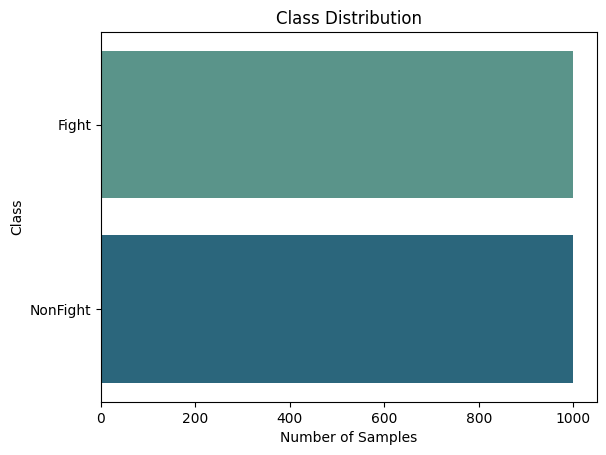

In [8]:
n_fight = n_train_fight + n_val_fight
n_nonfight = n_train_nonfight + n_val_nonfight

df = pd.DataFrame({
    "Class": ["Fight", "NonFight"],
    "Count": [n_fight, n_nonfight]
})

sns.barplot(data=df, x="Count", y="Class", hue="Class", palette='crest', legend=False)
plt.xlabel("Number of Samples")
plt.ylabel("Class")
plt.title("Class Distribution")
plt.show()

## Check for Corrupted Files

In [9]:
corrupted_files = []
for set_name in os.listdir(DATASET_PATH):
    for class_name in os.listdir(os.path.join(DATASET_PATH, set_name)):
        for vid_name in os.listdir(os.path.join(DATASET_PATH, set_name, class_name)):
            vid_path = os.path.join(DATASET_PATH, set_name, class_name, vid_name)
            if not os.path.isfile(vid_path):
                continue

            cap = cv2.VideoCapture(vid_path)
            if not cap.isOpened():
                corrupted_files.append(vid_path)
                cap.release()
                continue
            # Try reading at least one frame
            ret, frame = cap.read()
            if not ret or frame is None:
                corrupted_files.append(vid_path)
            cap.release()

print(f"Corrupted/unreadable videos: {len(corrupted_files)}")
if len(corrupted_files)!=0:
    print(corrupted_files)

Corrupted/unreadable videos: 0


## Video Statistics

In [10]:
def get_video_stats(video_path):
    # Open the video file
    video = cv2.VideoCapture(video_path)

    # Extract FPS and total frame count
    fps = video.get(cv2.CAP_PROP_FPS)
    frame_count = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

    # Calculate duration in seconds
    duration = frame_count / fps if fps > 0 else 0

    # Extract resolution
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Calculate Aspect Ratio
    aspect_ratio = width / height if height > 0 else 0

    # Codec
    fourcc = int(video.get(cv2.CAP_PROP_FOURCC))
    codec = "".join([
        chr((fourcc >> 0) & 0xFF),
        chr((fourcc >> 8) & 0xFF),
        chr((fourcc >> 16) & 0xFF),
        chr((fourcc >> 24) & 0xFF)
    ])

    # Bitrate (may not be available/reliable for every video)
    bitrate = video.get(cv2.CAP_PROP_BITRATE)

    # File size in MB
    file_size_mb = os.path.getsize(video_path) / (1024 * 1024)

    video.release()

    return {
        "fps": fps,
        "frame_count": frame_count,
        "duration": duration,
        "width": width,
        "height": height,
        "aspect_ratio": aspect_ratio,
        "codec": codec,
        "bitrate": bitrate,
        "file_size_mb": file_size_mb
    }

<h2>Create Metadata DataFrames</h2>

In [11]:
def create_video_dataframe(set="train"):
    if set == "train":
        set_dir = TRAIN_DATA_PATH
    elif set == "val":
        set_dir = VAL_DATA_PATH
    else:
        raise ValueError("set must be either 'train' or 'val'")

    data = []
    for class_name in ["Fight", "NonFight"]:
        video_dir = os.path.join(set_dir, class_name)
        for vid_name in os.listdir(video_dir):
            vid_path = os.path.join(video_dir, vid_name)
            if not os.path.isfile(vid_path):
                continue

            stats = get_video_stats(vid_path)
            # Combine filename, class and statistics
            row = {
                "filename": vid_name,
                "filepath": vid_path,
                "class": class_name,
                **stats
            }
            data.append(row)

    df = pd.DataFrame(data)
    return df

In [12]:
train_df = create_video_dataframe("train")
val_df = create_video_dataframe("val")

In [13]:
train_df.head()

,filename,filepath,class,fps,frame_count,duration,width,height,aspect_ratio,codec,bitrate,file_size_mb
0,p1bUxYeJ_1.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,320,240,1.333333,MJPG,4273.0,2.547497
1,gHcG_c1i4uE_0.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,632,360,1.755556,MJPG,7639.0,4.553635
2,чЫСцОзцЛНф╕ЛщдРхОЕф╕Ач╛дх░Пф╝ЩцЙУцЮ╢цЦЧцо┤ шАБ...,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,480,272,1.764706,MJPG,6281.0,3.744116
3,XRC_6WgxusI_0.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,352,288,1.222222,MJPG,4050.0,2.414497
4,4yTlGiDoxBo_1.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,480,360,1.333333,MJPG,5550.0,3.308517


In [14]:
val_df.head()

,filename,filepath,class,fps,frame_count,duration,width,height,aspect_ratio,codec,bitrate,file_size_mb
0,JECBfnp2ZXc_2.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,1280,720,1.777778,MJPG,10312.0,6.147015
1,RETYTDF_523.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,480,360,1.333333,MJPG,8703.0,5.187895
2,39BFeYnbu-I_7.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,640,360,1.777778,MJPG,8161.0,4.864735
3,1Kbw1bUw_0.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,320,240,1.333333,MJPG,3032.0,1.807516
4,48J5lk4QcpE_0.avi,/kaggle/input/datasets/vulamnguyen/rwf2000/RWF...,Fight,30.0,150,5.0,1280,720,1.777778,MJPG,19146.0,11.412201


Now, we have a metadata dataframe for our dataset. We can use these to analyse different statistics of videos now.

Now let's analyze the video stats.

In [15]:
print(train_df[["width", "height"]].describe())

             width       height
count  1600.000000  1600.000000
mean    717.751250   439.813750
std     437.824191   225.498423
min     204.000000   188.000000
25%     320.000000   240.000000
50%     528.000000   360.000000
75%    1280.000000   720.000000
max    1920.000000  1080.000000


<h3>Duration, FPS, Frame Count, Codec</h3>

In [16]:
print(train_df["duration"].value_counts())
print(val_df["duration"].value_counts())
print(train_df["fps"].value_counts())
print(val_df["fps"].value_counts())
print(train_df["frame_count"].value_counts())
print(val_df["frame_count"].value_counts())
print(train_df["codec"].value_counts())
print(val_df["codec"].value_counts())

duration
5.0    1600
Name: count, dtype: int64
duration
5.0    400
Name: count, dtype: int64
fps
30.0    1600
Name: count, dtype: int64
fps
30.0    400
Name: count, dtype: int64
frame_count
150    1600
Name: count, dtype: int64
frame_count
150    400
Name: count, dtype: int64
codec
MJPG    1600
Name: count, dtype: int64
codec
MJPG    400
Name: count, dtype: int64


Every video in the dataset has the same `frame count` , `fps` , `duration` and `codec` .

Make some new columns for visualization.

In [17]:
train_df["resolution"] = (train_df["width"].astype(str) + "x" + train_df["height"].astype(str))
val_df["resolution"] = (val_df["width"].astype(str) + "x" + val_df["height"].astype(str))
train_df["aspect_ratio_rounded"] = train_df["aspect_ratio"].round(1)
val_df["aspect_ratio_rounded"] = val_df["aspect_ratio"].round(1)

<h3>Resolution</h3>

**Resolution** ($width × height$): Shows whether videos have consistent or varied dimensions. Useful for deciding whether to resize videos and detecting very low/high-resolution outliers.

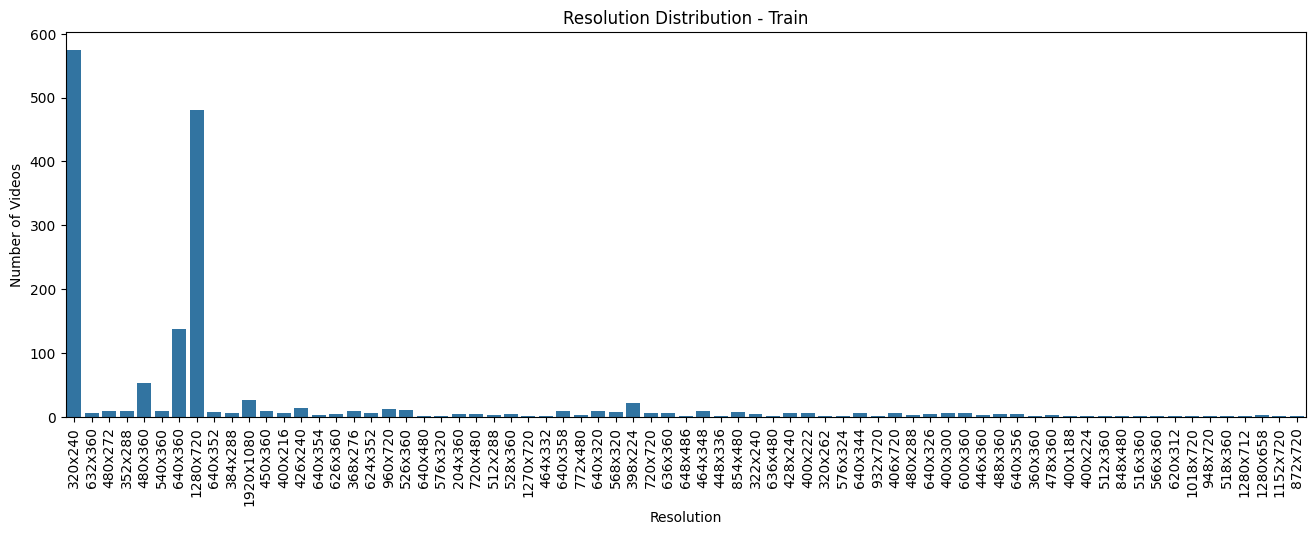

In [18]:
plt.figure(figsize=(16, 5))

sns.countplot(
    data=train_df,
    x="resolution"
)

plt.title("Resolution Distribution - Train")
plt.xlabel("Resolution")
plt.ylabel("Number of Videos")
plt.xticks(rotation=90)
plt.show()

In [19]:
train_df["resolution"].value_counts().iloc[:6]

resolution
320x240      574
1280x720     481
640x360      138
480x360       53
1920x1080     27
398x224       22
Name: count, dtype: int64

Most of the videos are of the resolutions `320x240` , `1280x720` , `640x360` and `480x360`

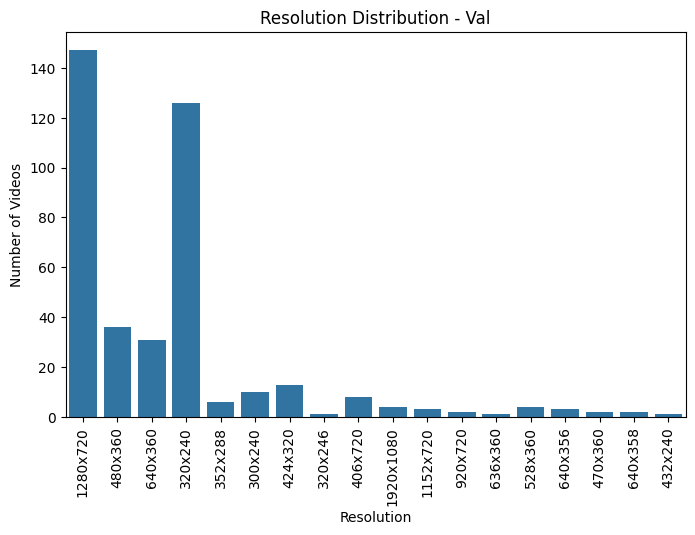

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=val_df,
    x="resolution"
)

plt.title("Resolution Distribution - Val")
plt.xlabel("Resolution")
plt.ylabel("Number of Videos")
plt.xticks(rotation=90  )
plt.show()

In [21]:
val_df["resolution"].value_counts().iloc[:6]

resolution
1280x720    147
320x240     126
480x360      36
640x360      31
424x320      13
300x240      10
Name: count, dtype: int64

> We can see that the videos of training and validation distributions have similar `resolutions`.

<h3>Aspect Ratio</h3>

**Aspect ratio** ($width$ / $height$): Shows the shape of videos (e.g., 16:9, 4:3). Helps detect unusual formats and prevents distortion when resizing or cropping.

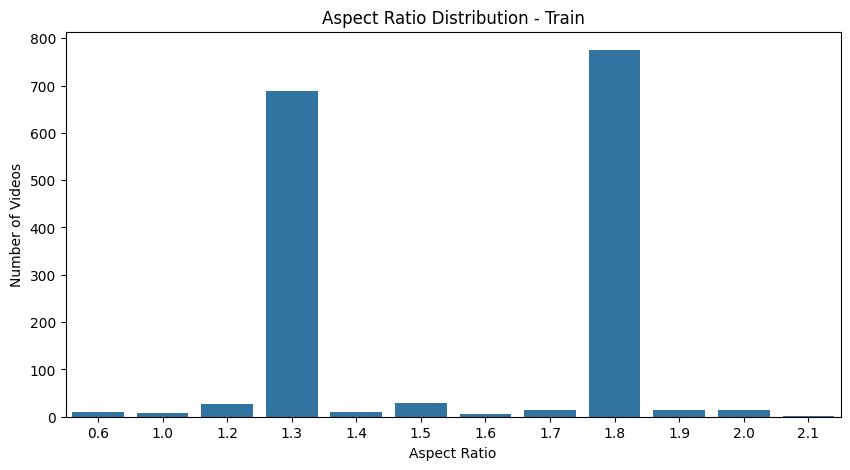

In [22]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="aspect_ratio_rounded"
)

plt.title("Aspect Ratio Distribution - Train")
plt.xlabel("Aspect Ratio")
plt.ylabel("Number of Videos")
plt.show()

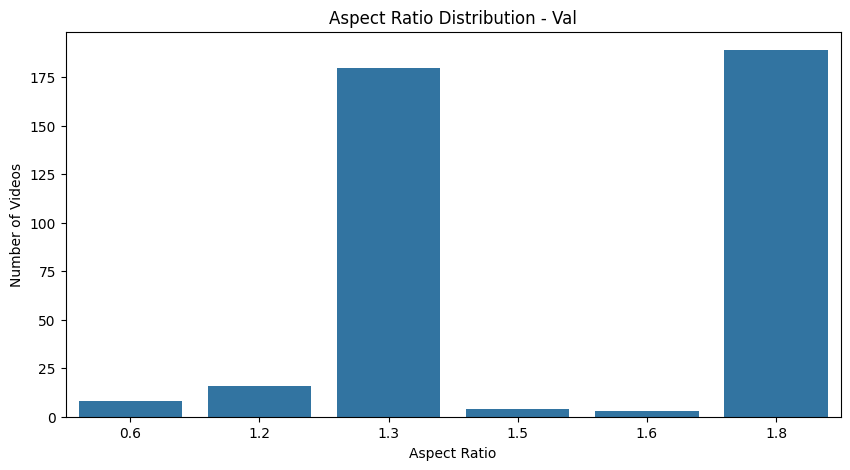

In [23]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=val_df,
    x="aspect_ratio_rounded"
)

plt.title("Aspect Ratio Distribution - Val")
plt.xlabel("Aspect Ratio")
plt.ylabel("Number of Videos")
plt.show()

> As it was observed above that videos of training and validation distributions have similar `resolutions`, it also holds true for `aspect ratio` .

<h3>File size</h3>

**File size**: Shows how much storage each video requires. Helps identify unusually large files, estimate storage needs, and spot possible outliers or compression differences.

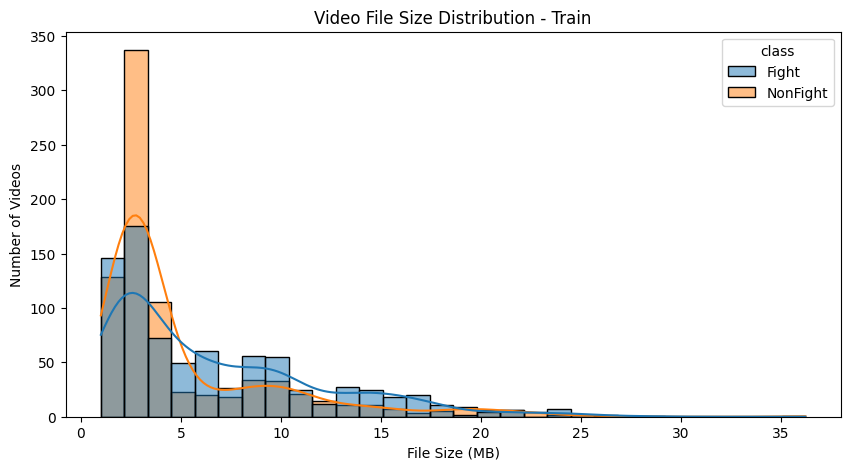

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="file_size_mb",
    hue="class",
    kde=True,
    bins=30
)

plt.title("Video File Size Distribution - Train")
plt.xlabel("File Size (MB)")
plt.ylabel("Number of Videos")
plt.show()

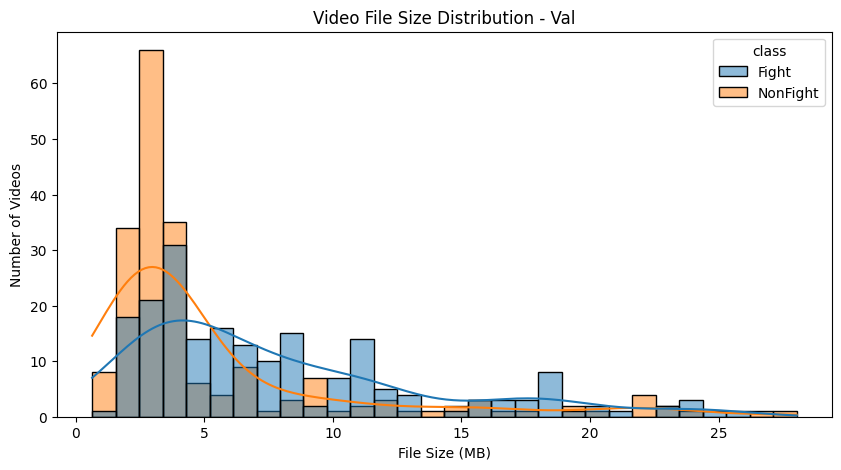

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=val_df,
    x="file_size_mb",
    hue="class",
    kde=True,
    bins=30
)

plt.title("Video File Size Distribution - Val")
plt.xlabel("File Size (MB)")
plt.ylabel("Number of Videos")
plt.show()

> Most of the videos are less than or equal to 20MB of file size. Maximum size is ~35MB.

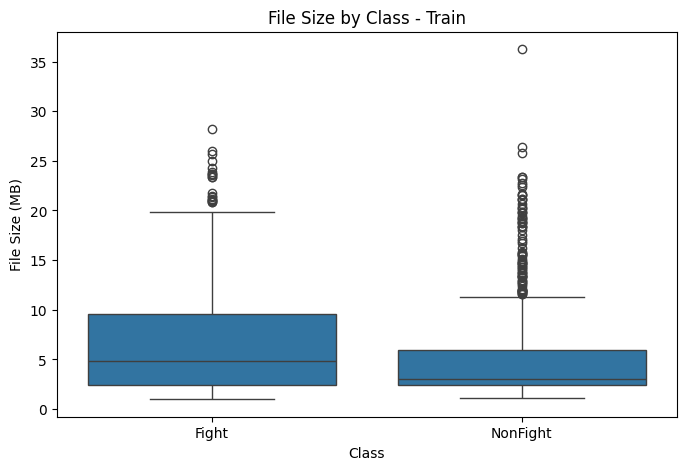

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="class",
    y="file_size_mb"
)

plt.title("File Size by Class - Train")
plt.xlabel("Class")
plt.ylabel("File Size (MB)")
plt.show()

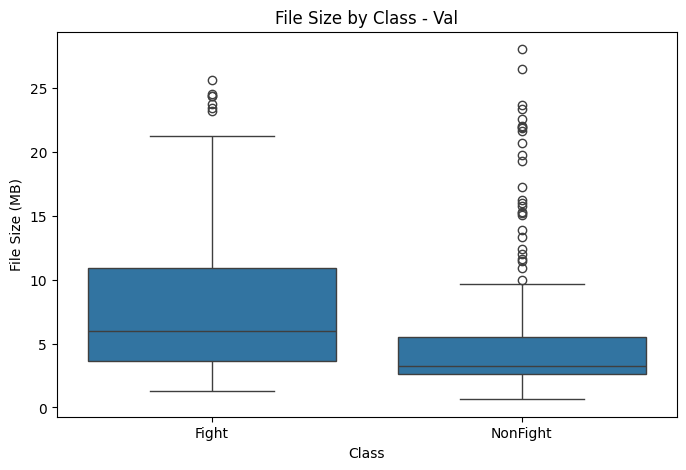

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=val_df,
    x="class",
    y="file_size_mb"
)

plt.title("File Size by Class - Val")
plt.xlabel("Class")
plt.ylabel("File Size (MB)")
plt.show()

> File size trends are also similar for training and validation distributions.

<h3>Bitrate</h3>

**Bitrate**: Indicates how much data is used to represent the video per second. Plotting it helps understand video quality/compression differences and identify unusually high or low bitrate videos.

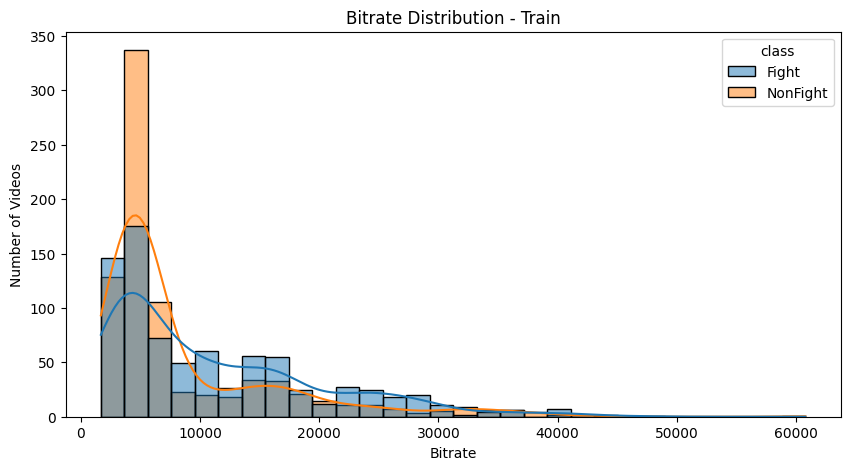

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="bitrate",
    hue="class",
    kde=True,
    bins=30
)

plt.title("Bitrate Distribution - Train")
plt.xlabel("Bitrate")
plt.ylabel("Number of Videos")
plt.show()

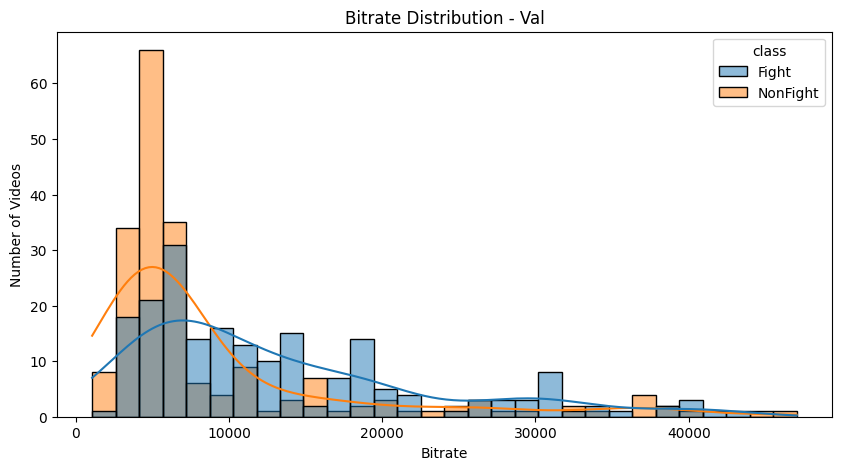

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=val_df,
    x="bitrate",
    hue="class",
    kde=True,
    bins=30
)

plt.title("Bitrate Distribution - Val")
plt.xlabel("Bitrate")
plt.ylabel("Number of Videos")
plt.show()

> As for the `File size` , `Bitrate` also have similar distributions for training and validation distributions.

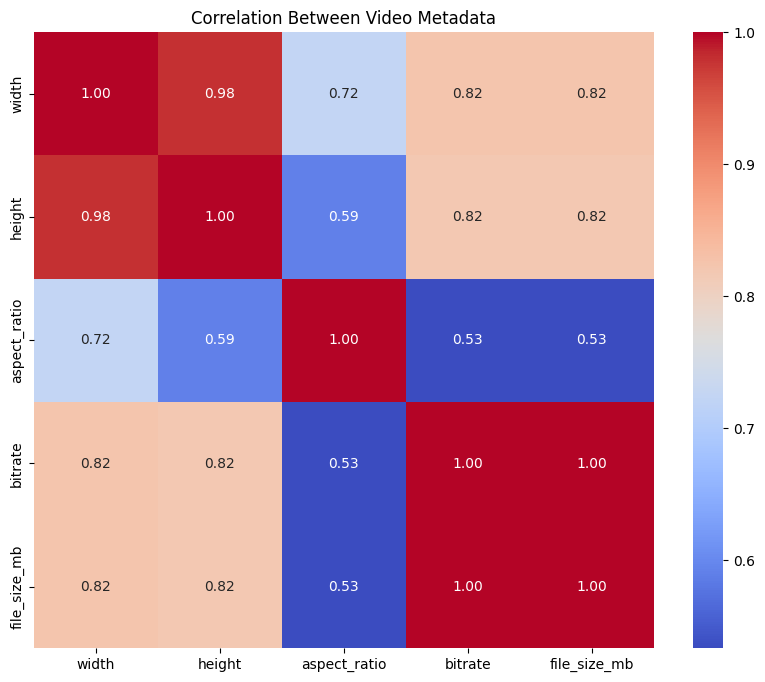

In [30]:
numeric_cols = [
    "width",
    "height",
    "aspect_ratio",
    "bitrate",
    "file_size_mb",
]

plt.figure(figsize=(10, 8))
sns.heatmap(
    train_df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Video Metadata")
plt.show()

> ***So, as observed from the metadata of the videos from both training and validation distributions, data shows similar distributions for metadata like FPS, frame count, duration, resolution, aspect ratio, file size and bitrate***

## Load Frames from a video

In [31]:
def sample_frames(video_path, n_frames=16):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    indices = np.linspace(0, total_frames - 1, n_frames, dtype=int)

    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()

        if ret:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)

    cap.release()
    return frames

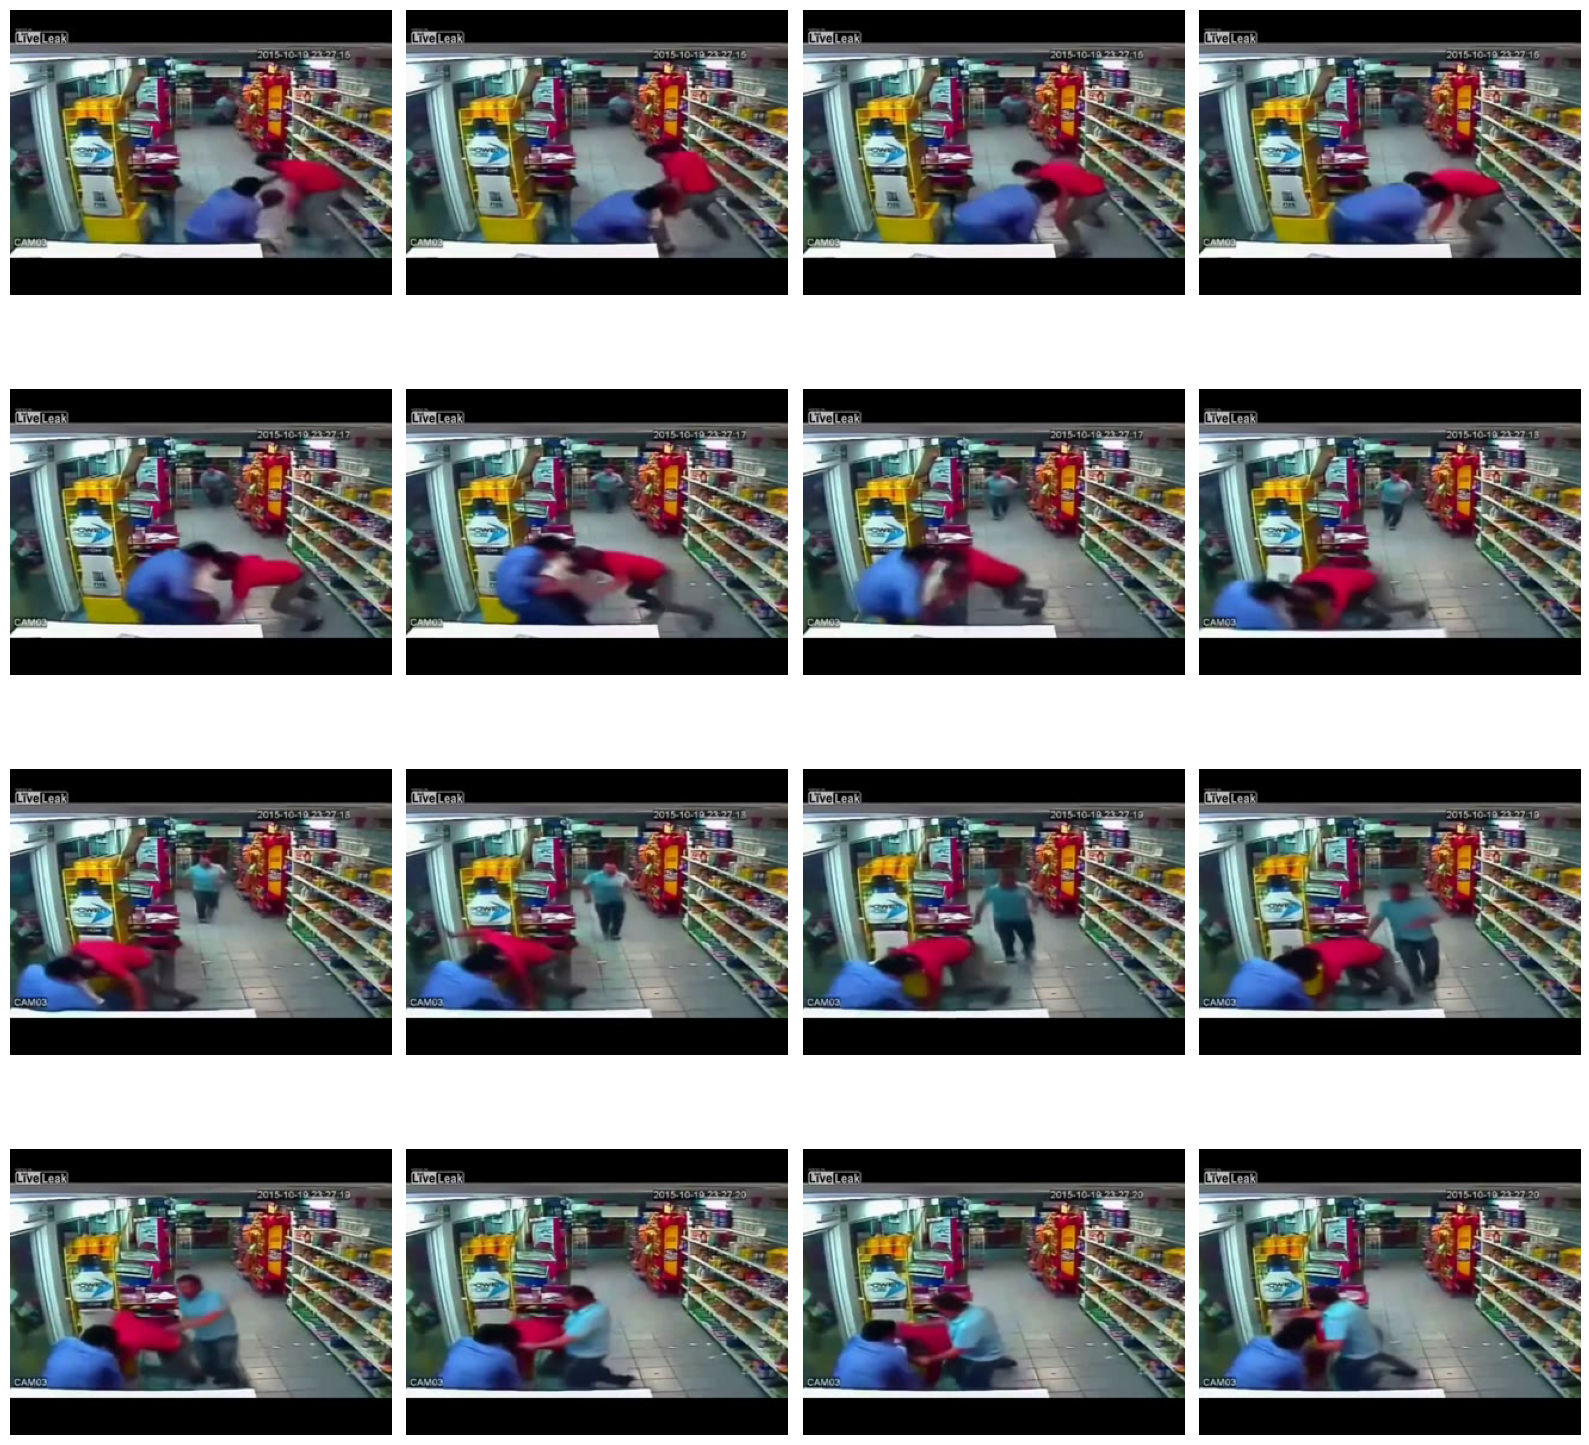

In [32]:
frames = sample_frames(train_df[train_df["class"] == "Fight"].iloc[0]["filepath"])

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for ax, frame in zip(axes.flat, frames):
    ax.imshow(frame)
    ax.axis("off")

plt.tight_layout()
plt.show()

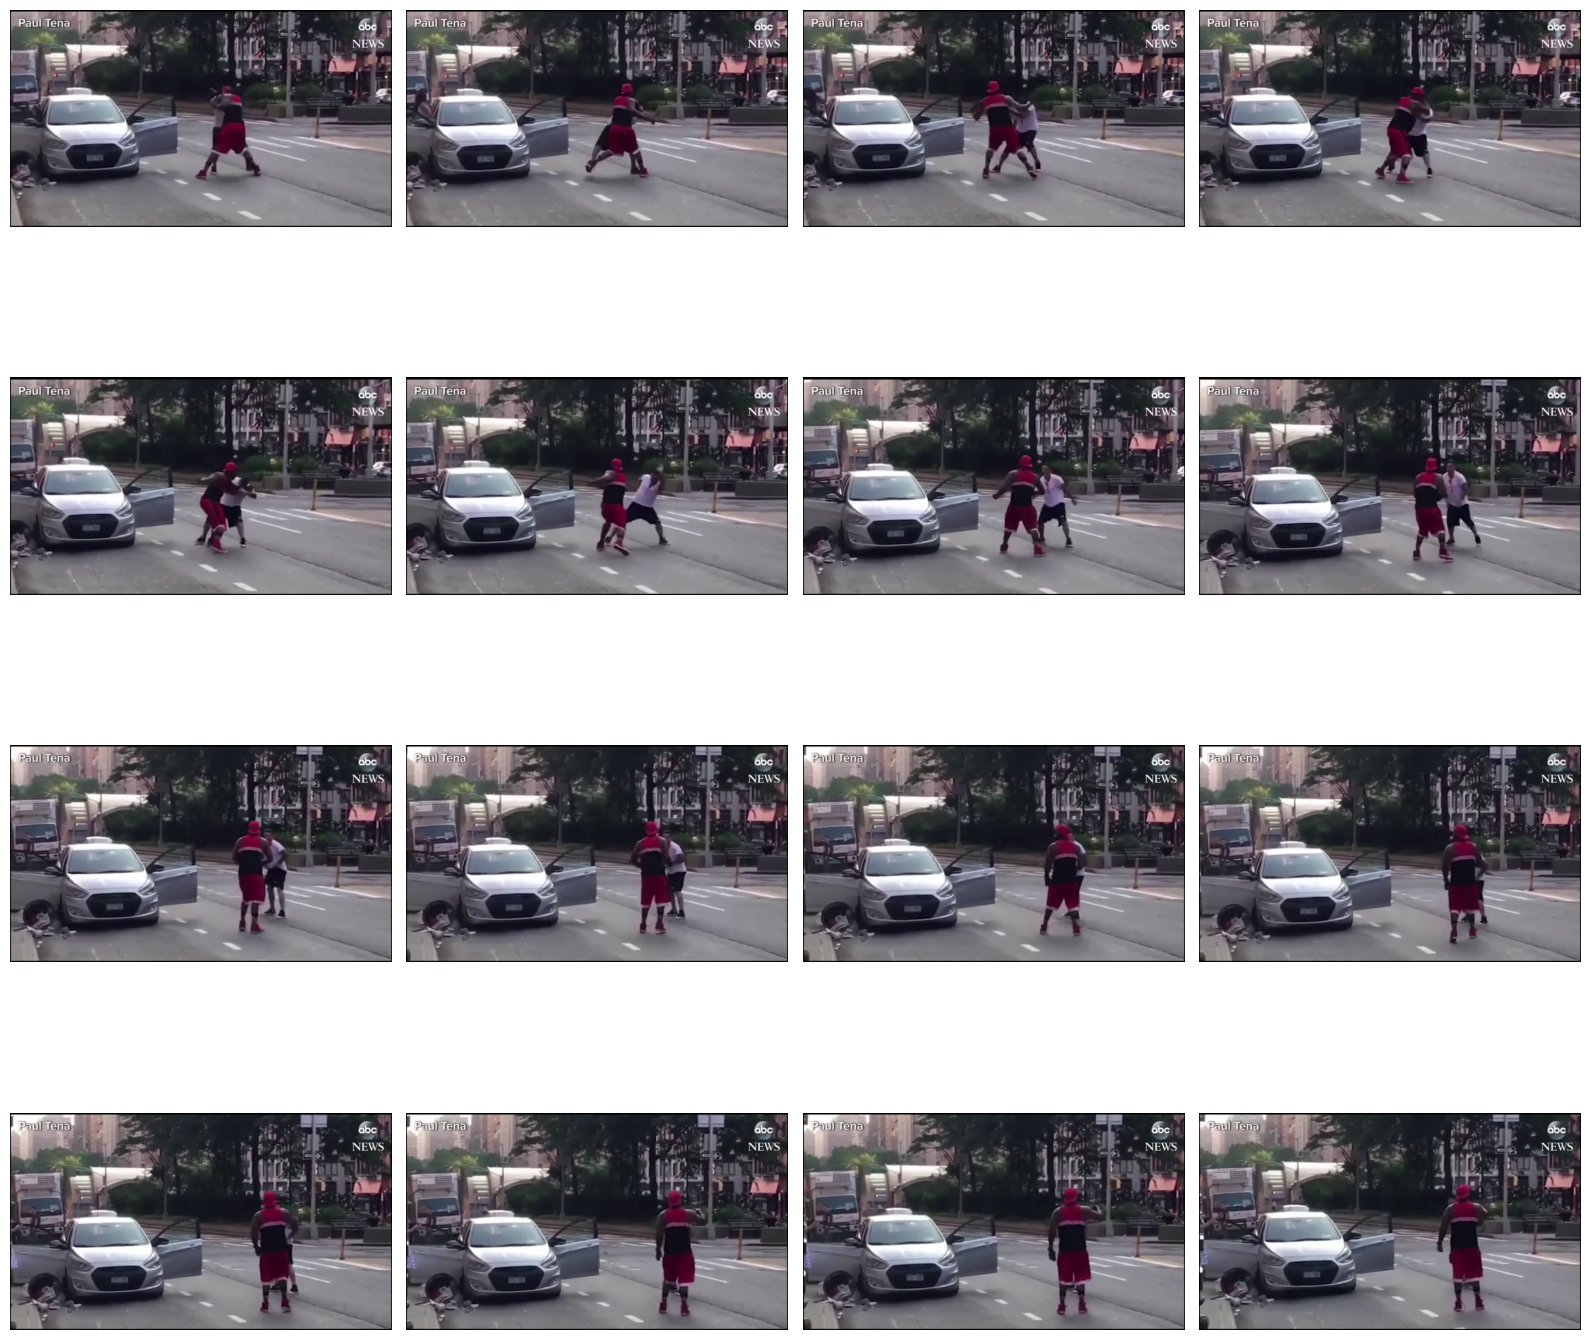

In [33]:
frames = sample_frames(train_df[train_df["class"] == "Fight"].iloc[1]["filepath"])

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for ax, frame in zip(axes.flat, frames):
    ax.imshow(frame)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Data Loading Pipeline

Now, as we proceed toward model training, it is important to understand how a model is trained on a video dataset. The overall process follows the usual machine learning lifecycle:

- The data is split into train/val/test distributions.

- Similar to an image dataset, the videos need to be converted into tensors before they can be passed to the model. However, *videos contain a temporal dimension in addition to the spatial dimensions of an image*.

- For each video, we select a fixed number of frames and resize each frame to a common spatial resolution. These frames are then stacked together to form a **video tensor** with the shape: \
`(frames, height, width, channels)`

- For example, in this solution, each video is represented using `16` frames, with each frame resized to `112 × 112` pixels and represented using `3` RGB channels. Therefore, each video is converted into a tensor of shape: \
`(16, 112, 112, 3)`

- A `batch_size` number of these video tensors are then accumulated to form a batch. Consequently, the input to the model has the shape: \
`(batch_size, frames, height, width, channels)`

- In our case, with a batch size of `2`, the input shape is: \
`(16, 16, 112, 112, 3)`

The data-loading pipeline can also prefetch batches so that the next batch is prepared while the model is processing the current batch. This helps keep the training process efficient.

<div align="center">
    <img width=500 src="https://miro.medium.com/v2/1*k7vC95vYHyUNh9F2iYU-Lg.png">
</div>

**config**

In [34]:
SEED = 42
NUM_FRAMES = 16
IMG_SIZE = 160
CHANNELS = 3

NUM_GPUS = torch.cuda.device_count()
PER_GPU_BATCH_SIZE = 8
BATCH_SIZE = PER_GPU_BATCH_SIZE * max(NUM_GPUS, 1)
NUM_WORKERS = min(4 * max(NUM_GPUS, 1), os.cpu_count() or 4)
PREFETCH_FACTOR = 2

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("GPU count:", NUM_GPUS)
print("Global batch size:", BATCH_SIZE)
print("Per-GPU batch size:", PER_GPU_BATCH_SIZE)
print("DataLoader workers:", NUM_WORKERS)

Device: cuda
GPU count: 2
Global batch size: 16
Per-GPU batch size: 8
DataLoader workers: 4


## Train / Validation / Test Split

In [35]:
from sklearn.model_selection import train_test_split

class_to_label = {
    "NonFight": 0,
    "Fight": 1
}

# Train folder videos paths
all_train_paths = train_df["filepath"].astype(str).values
all_train_labels = train_df["class"].map(class_to_label).astype(np.int64).values
# Make the split
train_paths, val_paths, train_labels, val_labels = train_test_split(all_train_paths, all_train_labels, test_size=0.20, random_state=SEED, stratify=all_train_labels, shuffle=True)
# Validation folder videos paths
test_paths = val_df["filepath"].astype(str).values
test_labels = val_df["class"].map(class_to_label).astype(np.int64).values

print("Training samples:", len(train_paths))
print("Validation samples:", len(val_paths))
print("Test samples:", len(test_paths))
print("----------------------------")
print("Training distribution:")
unique, counts = np.unique(train_labels, return_counts=True)
print(dict(zip(unique, counts)))

print("Validation distribution:")
unique, counts = np.unique(val_labels, return_counts=True)
print(dict(zip(unique, counts)))

print("Test distribution:")
unique, counts = np.unique(test_labels, return_counts=True)
print(dict(zip(unique, counts)))

Training samples: 1280
Validation samples: 320
Test samples: 400
----------------------------
Training distribution:
{np.int64(0): np.int64(640), np.int64(1): np.int64(640)}
Validation distribution:
{np.int64(0): np.int64(160), np.int64(1): np.int64(160)}
Test distribution:
{np.int64(0): np.int64(200), np.int64(1): np.int64(200)}


In [36]:
# PyTorch imports
import torch.nn as nn
import torch.optim as optim
import torchvision
from torch.utils.data import Dataset, DataLoader

In [37]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

PyTorch version: 2.10.0+cu128
Device: cuda
CUDA available: True
CUDA version: 12.8
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


**Dataset**

In [38]:
from torchvision.transforms import v2 as T
class VideoPre:
    """uint8 (T,C,H,W) -> float (C,T,H,W), normalised. Whole frame is kept (no center crop)."""
    def __init__(self, train, size=160):
        self.mean, self.std = X3D_MEAN, X3D_STD
        if train:
            big = int(round(size * 1.1))
            self.spatial = T.Compose([
                T.Resize((big, big), antialias=True),
                # same crop for every frame of the clip (torchvision v2 treats T as a batch dim)
                T.RandomResizedCrop((size, size), scale=(0.5, 1.0), ratio=(0.8, 1.25), antialias=True),
            ])
        else:
            self.spatial = T.Resize((size, size), antialias=True)
        self.normalize = T.Normalize(self.mean, self.std)
 
    def __call__(self, video_uint8):
        x = self.spatial(video_uint8)                 # T,C,H,W uint8
        x = self.normalize(x.float() / 255.0)         # T,C,H,W float
        return x.permute(1, 0, 2, 3).contiguous()     # C,T,H,W
 
X3D_MEAN = (0.45, 0.45, 0.45)         # pytorchvideo's Kinetics normalisation
X3D_STD = (0.225, 0.225, 0.225)
train_pre = VideoPre(train=True, size=IMG_SIZE)
eval_pre = VideoPre(train=False, size=IMG_SIZE)

**Fast data pipeline (replaces the per-epoch video decoding):** decode every video once into a uint8 cache, then read from it and do augmentation on the GPU.

In [39]:
import torch.nn.functional as F

cv2.setNumThreads(1)                         # stop OpenCV from spawning its own threads on top of ours

CACHE_FRAMES = 32                            # 2 candidate frames per training segment (temporal jitter)
CACHE_SIZE   = int(round(IMG_SIZE * 1.1))    # same "big" size the old Resize used
CACHE_DIR    = "/kaggle/working/cache"
os.makedirs(CACHE_DIR, exist_ok=True)

def read_cached_frames(path, n=CACHE_FRAMES, size=CACHE_SIZE):
    """Decode ONE video sequentially (no seeking), keep n evenly spaced frames, resize, RGB uint8."""
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    seg = total / n
    want = set(min(int((i + 0.5) * seg), total - 1) for i in range(n))
    out, last, idx = [], None, 0
    while len(out) < n:
        if not cap.grab():
            break
        if idx in want:
            ok, fr = cap.retrieve()
            if ok:
                fr = cv2.resize(fr, (size, size), interpolation=cv2.INTER_AREA)
                last = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
                out.append(last)
        idx += 1
    cap.release()
    while len(out) < n:                      # broken/short video -> repeat last frame
        out.append(last if last is not None else np.zeros((size, size, 3), np.uint8))
    return np.stack(out)

def build_cache(paths, labels, name):
    x_path = f"{CACHE_DIR}/{name}_x.npy"
    if os.path.exists(x_path):
        print(f"{name}: cache already exists, skipping"); return
    mm = np.lib.format.open_memmap(x_path, mode="w+", dtype=np.uint8,
                                   shape=(len(paths), CACHE_FRAMES, CACHE_SIZE, CACHE_SIZE, 3))
    with Pool(os.cpu_count() or 4) as pool:
        for i, clip in enumerate(tqdm(pool.imap(read_cached_frames, list(paths), chunksize=4),
                                      total=len(paths), desc=name)):
            mm[i] = clip                     # imap keeps order, so row i == paths[i]
    mm.flush(); del mm
    np.save(f"{CACHE_DIR}/{name}_y.npy", np.asarray(labels, dtype=np.int64))

# One-time cost: each video is decoded exactly once, here.
build_cache(train_paths, train_labels, "train")
build_cache(val_paths,   val_labels,   "val")
build_cache(test_paths,  test_labels,  "test")


train:   0%|          | 0/1280 [00:00<?, ?it/s]

val:   0%|          | 0/320 [00:00<?, ?it/s]

test:   0%|          | 0/400 [00:00<?, ?it/s]

In [40]:
class CachedClips(Dataset):
    """Reads pre-decoded uint8 frames from a memory-mapped .npy file. Almost no CPU work."""
    def __init__(self, name, training=False):
        self.x = np.load(f"{CACHE_DIR}/{name}_x.npy", mmap_mode="r")   # N,32,S,S,3
        self.labels = np.load(f"{CACHE_DIR}/{name}_y.npy")
        self.training = training
        self.base = 2 * np.arange(NUM_FRAMES)                          # first frame of each segment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        # train: random one of the 2 cached frames per segment; eval: fixed (deterministic)
        pick = self.base + (np.random.randint(0, 2, NUM_FRAMES) if self.training else 0)
        clip = torch.from_numpy(np.ascontiguousarray(self.x[i][pick]))  # T,S,S,3 uint8
        return clip, torch.tensor(self.labels[i], dtype=torch.long)

In [41]:
# ---- augmentation + normalisation on the GPU (replaces VideoPre / augment_video)
_MEAN = torch.tensor(X3D_MEAN, device=device).view(1, 3, 1, 1, 1)
_STD  = torch.tensor(X3D_STD,  device=device).view(1, 3, 1, 1, 1)

def gpu_prepare(v, training):
    """v: B,T,S,S,3 uint8 on GPU  ->  B,3,T,IMG_SIZE,IMG_SIZE float, normalised."""
    v = v.permute(0, 4, 1, 2, 3).float().div_(255.0)            # B,C,T,S,S
    B, C, T, S, _ = v.shape
    if training:
        clips = []
        for b in range(B):
            x = v[b]                                              # C,T,S,S
            # same random-resized-crop for every frame of the clip
            area  = S * S * random.uniform(0.5, 1.0)
            ratio = math.exp(random.uniform(math.log(0.8), math.log(1.25)))
            w = min(S, int(round(math.sqrt(area * ratio))))
            h = min(S, int(round(math.sqrt(area / ratio))))
            top, left = random.randint(0, S - h), random.randint(0, S - w)
            x = x[:, :, top:top + h, left:left + w]
            x = F.interpolate(x.permute(1, 0, 2, 3), size=(IMG_SIZE, IMG_SIZE),
                              mode="bilinear", align_corners=False).permute(1, 0, 2, 3)
            if random.random() < 0.5:                             # horizontal flip
                x = x.flip(-1)
            if random.random() < 0.5:                             # brightness
                x = (x + random.uniform(-0.10, 0.10)).clamp_(0.0, 1.0)
            clips.append(x)
        v = torch.stack(clips)
    else:
        x = v.permute(0, 2, 1, 3, 4).reshape(B * T, C, S, S)
        x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
        v = x.reshape(B, T, C, IMG_SIZE, IMG_SIZE).permute(0, 2, 1, 3, 4)
    return ((v - _MEAN) / _STD).contiguous()

class GPULoader:
    """Wraps a DataLoader; yields batches that are already on the GPU, augmented and normalised.
    train_one_epoch / evaluate keep working unchanged (their .to(device) becomes a no-op)."""
    def __init__(self, loader, training):
        self.loader, self.training = loader, training
    def __len__(self):
        return len(self.loader)
    def __iter__(self):
        for v, y in self.loader:
            v = v.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            yield gpu_prepare(v, self.training), y


**DataLoaders**

In [42]:
NUM_WORKERS = 2          # loading is now just a memmap slice, so a couple of workers is plenty

def make_loader(name, training, shuffle, drop_last=False):
    ds = CachedClips(name, training=training)
    dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                    pin_memory=torch.cuda.is_available(), persistent_workers=NUM_WORKERS > 0,
                    prefetch_factor=4 if NUM_WORKERS > 0 else None, drop_last=drop_last)
    return GPULoader(dl, training)

train_loader = make_loader("train", training=True,  shuffle=True, drop_last=True)
val_loader = make_loader("val",   training=False, shuffle=False)
test_loader = make_loader("test",  training=False, shuffle=False)
# NOTE: the old train_eval_loader used training=True (random aug) - for a clean train-set
# evaluation it should be deterministic, so it is training=False here.
train_eval_loader = make_loader("train", training=False, shuffle=False)

videos, labels = next(iter(train_loader))
print("Video batch shape:", videos.shape, videos.dtype, videos.device)
print("Labels:", labels)

Video batch shape: torch.Size([16, 3, 16, 160, 160]) torch.float32 cuda:0
Labels: tensor([1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0], device='cuda:0')


# Model Training

In [43]:
from pytorchvideo.models.hub import x3d_s, x3d_m
X3D_VARIANT = "x3d_s"
def build_x3d(variant="x3d_s", num_classes=2):
    factory = {"x3d_s": x3d_s, "x3d_m": x3d_m}[variant]
    m = factory(pretrained=True) # downloads Kinetics weights
    head = m.blocks[5]
    head.proj = nn.Linear(head.proj.in_features, num_classes)   # 2048 -> 2
    return m
 
 
model_base = build_x3d(X3D_VARIANT).to(device)
 
if NUM_GPUS > 1:
    model = nn.DataParallel(model_base, device_ids=list(range(NUM_GPUS)), output_device=0)
else:
    model = model_base

for param in model_base.parameters():
    param.requires_grad = False
for param in model_base.blocks[5].proj.parameters():
    param.requires_grad = True

Downloading: "https://dl.fbaipublicfiles.com/pytorchvideo/model_zoo/kinetics/X3D_S.pyth" to /root/.cache/torch/hub/checkpoints/X3D_S.pyth


100%|██████████| 29.4M/29.4M [00:00<00:00, 42.0MB/s]


In [44]:
criterion = nn.CrossEntropyLoss()
optimizer0 = optim.AdamW(model_base.blocks[5].proj.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler0 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer0,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

<h3>Auto Mixed Precision</h3>

In [45]:
# We will use Auto Mixed Precision
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda",enabled=use_amp)
print("AMP enabled:", use_amp)

AMP enabled: True


<h3>Train Epoch</h3>

In [46]:
from tqdm import tqdm

def train_one_epoch(model, loader, criterion, optimizer, scaler, device, use_amp=True, freeze_backbone=False):
    def set_frozen_backbone_mode(model):
        base = model.module if isinstance(model, nn.DataParallel) else model
        base.eval()                        # BN statistics stay fixed
        base.blocks[5].dropout.train()     # head dropout (0.5) still active
        base.blocks[5].proj.train()
    # model.train()
    if freeze_backbone:
        # model_base = model.module if isinstance(model, nn.DataParallel) else model
        # model_base.eval()
        # model_base.fc.train()
        set_frozen_backbone_mode(model)

    running_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device, dtype=torch.long)
    total = 0
    all_predictions = []
    all_labels = []

    progress_bar = tqdm(loader, total=len(loader), leave=True, colour="#00A86B", ncols=120,
        bar_format=(
            "{n_fmt}/{total_fmt} "
            "{bar:20} "
            "{elapsed} "
            "{postfix}"
        )
    )

    epoch_start = time.time()
    for step, (videos, labels) in enumerate(progress_bar, start=1):
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(videos)
            loss = criterion(outputs, labels)

        # Backpropagation
        scaler.scale(loss).backward()
        # Gradient clipping
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.detach() * videos.size(0)
        predictions = torch.argmax(outputs, dim=1)
        correct += (predictions == labels).sum()
        total += videos.size(0)

        if step == 1 or step % 20 == 0 or step == len(loader):
            current_loss = running_loss / total
            current_acc = correct / total
            elapsed = time.time() - epoch_start
            ms_per_step = (elapsed / (progress_bar.n + 1)) * 1000
            progress_bar.set_postfix_str(
                f"{ms_per_step:.0f}ms/step - "
                f"loss: {current_loss:.4f} - "
                f"accuracy: {current_acc:.4f}"
            )

    epoch_loss = (running_loss / total).item()
    epoch_accuracy = (correct.float() / total).item()

    return epoch_loss, epoch_accuracy, progress_bar, epoch_start

<h3>Validation</h3>

In [47]:
@torch.no_grad()
def evaluate(model, loader, criterion, device, use_amp=True):
    model.eval()
    running_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device, dtype=torch.long)
    total = 0
    all_predictions = []
    all_labels = []
    all_probabilities = []

    for videos, labels in loader:
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(videos)
            loss = criterion(outputs,labels)

        running_loss += loss.detach() * videos.size(0)
        predictions = torch.argmax(outputs, dim=1)
        probabilities = torch.softmax(outputs, dim=1)
        correct += (predictions == labels).sum()
        total += videos.size(0)
        
        all_labels.append(labels)
        all_predictions.append(predictions)
        all_probabilities.append(probabilities[:, 1])

    epoch_loss = (running_loss / total).item()
    epoch_accuracy = (correct.float() / total).item()
    all_labels = torch.cat(all_labels).cpu().numpy()
    all_predictions = torch.cat(all_predictions).cpu().numpy()
    all_probabilities = torch.cat(all_probabilities).cpu().numpy()
    
    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions,
        all_probabilities
    )

## Feature Extraction

In [48]:
NUM_EPOCHS = 7
best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    start_time = time.time()
    # Training
    train_loss, train_acc, progress_bar, epoch_start = train_one_epoch(model=model, loader=train_loader, criterion=criterion, optimizer=optimizer0, scaler=scaler, device=device, use_amp=use_amp, freeze_backbone=True)
    # Validation
    val_loss, val_acc, val_labels_epoch, val_predictions_epoch, val_probabilities_epoch = evaluate(model=model, loader=val_loader, criterion=criterion, device=device, use_amp=use_amp)
    progress_bar.write(
        f"val_loss: {val_loss:.4f} - "
        f"val_accuracy: {val_acc:.4f}"
    )
    
    # Scheduler
    scheduler0.step(val_loss)
    # Current learning rates
    current_lr = optimizer0.param_groups[0]["lr"]
    epoch_time = time.time() - start_time
    ms_per_step = (epoch_time / len(train_loader)) * 1000
    # Progress bar
    progress_bar.set_postfix_str(
        f"{ms_per_step:.0f}ms/step - "
        f"accuracy: {train_acc:.4f} - "
        f"loss: {train_loss:.4f} - "
        f"val_accuracy: {val_acc:.4f} - "
        f"val_loss: {val_loss:.4f} - "
        f"learning_rate: {current_lr:.4f}"
    )
    progress_bar.close()
    # Save history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    
    # Checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_base.state_dict(),
                "optimizer_state_dict": optimizer0.state_dict(),
                "scheduler_state_dict": scheduler0.state_dict(),
                "val_loss": val_loss,
                "val_accuracy": val_acc
            },
            "best_x3ds_rwf2000_stage1.pth"
        )
        epochs_without_improvement = 0
        print("✓ Saved model to best_x3ds_rwf2000_stage1.pth")

    else:
        epochs_without_improvement += 1
        print(f"No improvement for {epochs_without_improvement} epoch(s)")


Epoch 1/7


80/80 ████████████████████ 00:37 , 466ms/step - loss: 0.5589 - accuracy: 0.7695 


val_loss: 0.4903 - val_accuracy: 0.8188
✓ Saved model to best_x3ds_rwf2000_stage1.pth

Epoch 2/7


80/80 ████████████████████ 00:33 , 419ms/step - loss: 0.4854 - accuracy: 0.8516


val_loss: 0.4696 - val_accuracy: 0.8562
✓ Saved model to best_x3ds_rwf2000_stage1.pth

Epoch 3/7


...

val_loss: 0.4521 - val_accuracy: 0.8562
✓ Saved model to best_x3ds_rwf2000_stage1.pth

Epoch 6/7


80/80 ████████████████████ 00:33 , 423ms/step - loss: 0.4444 - accuracy: 0.8766


val_loss: 0.4446 - val_accuracy: 0.8844
✓ Saved model to best_x3ds_rwf2000_stage1.pth

Epoch 7/7


80/80 ████████████████████ 00:33 , 421ms/step - loss: 0.4465 - accuracy: 0.8781


val_loss: 0.4423 - val_accuracy: 0.8844
✓ Saved model to best_x3ds_rwf2000_stage1.pth


### Learning Curves

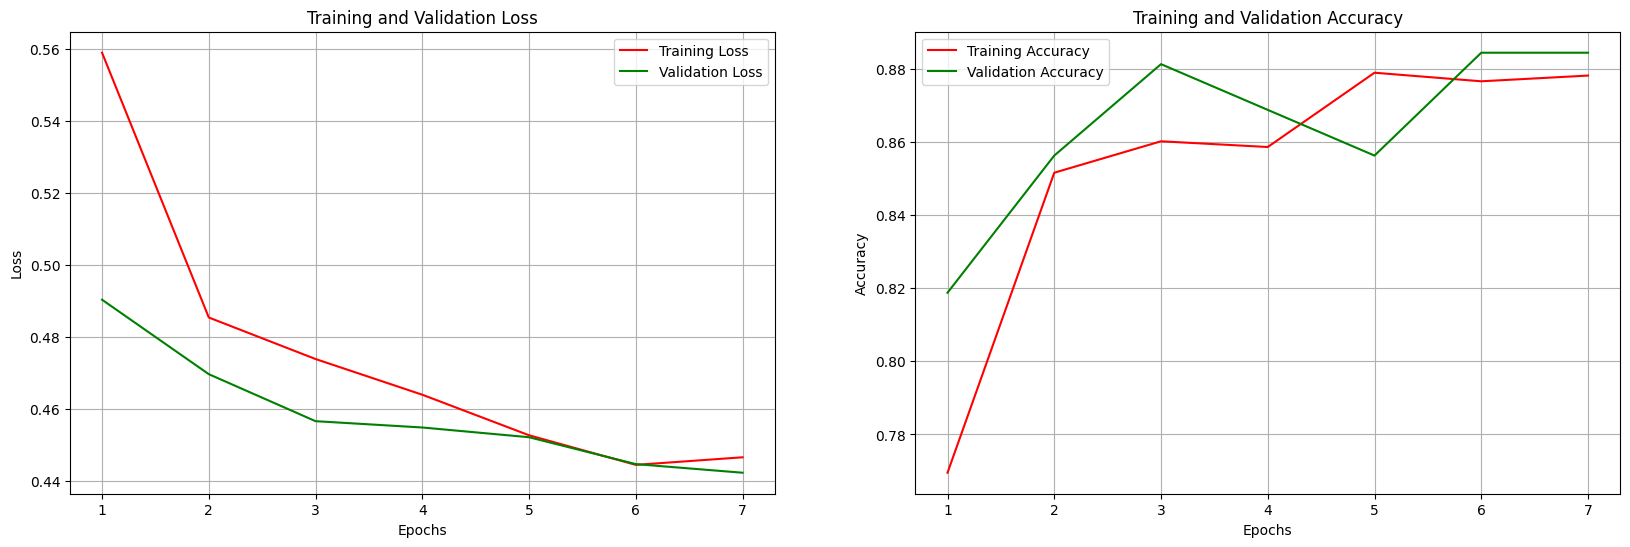

In [49]:
Epochs = [i + 1 for i in range(len(history["train_loss"]))]
plt.figure(figsize=(20, 6))

plt.subplot(1, 2, 1)
plt.plot(Epochs, history["train_loss"], 'r', label='Training Loss')
plt.plot(Epochs, history["val_loss"], 'g', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(Epochs, history["train_acc"], 'r', label='Training Accuracy')
plt.plot(Epochs, history["val_acc"], 'g', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
fig.savefig("/kaggle/working/learning_curves1.png", dpi=150, bbox_inches="tight")
plt.show()

## Fine Tuning

In [50]:
checkpoint = torch.load("best_x3ds_rwf2000_stage1.pth", map_location=device)
model_base.load_state_dict(checkpoint["model_state_dict"])
print(f"Loaded best Stage-1 model from epoch {checkpoint['epoch']}")

for param in model_base.parameters():
    param.requires_grad = True

blocks = model_base.blocks

optimizer1 = torch.optim.AdamW(
    [
        {"params": list(blocks[0].parameters()) + list(blocks[1].parameters()) + list(blocks[2].parameters()),
         "lr": 3e-5},                                   # stem + first two residual stages
        {"params": list(blocks[3].parameters()) + list(blocks[4].parameters()), "lr": 1e-4},
        {"params": blocks[5].parameters(), "lr": 3e-4},  # head (pre/post conv + new classifier)
    ],
    weight_decay=1e-2,
)

scheduler1 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer1,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

Loaded best Stage-1 model from epoch 7


In [51]:
NUM_EPOCHS = 30
PATIENCE = 6
best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    start_time = time.time()
    # Training
    train_loss, train_acc, progress_bar, epoch_start = train_one_epoch(model=model, loader=train_loader, criterion=criterion, optimizer=optimizer1, scaler=scaler, device=device, use_amp=use_amp)
    # Validation
    val_loss, val_acc, val_labels_epoch, val_predictions_epoch, val_probabilities_epoch = evaluate(model=model, loader=val_loader, criterion=criterion, device=device, use_amp=use_amp)
    progress_bar.write(
        f"val_loss: {val_loss:.4f} - "
        f"val_accuracy: {val_acc:.4f}"
    )
    # Scheduler
    scheduler1.step(val_loss)
    # Current learning rates
    current_lr = optimizer1.param_groups[0]["lr"]
    epoch_time = time.time() - start_time
    ms_per_step = (epoch_time / len(train_loader)) * 1000
    # Progress bar
    progress_bar.set_postfix_str(
        f"{ms_per_step:.0f}ms/step - "
        f"accuracy: {train_acc:.4f} - "
        f"loss: {train_loss:.4f} - "
        f"val_accuracy: {val_acc:.4f} - "
        f"val_loss: {val_loss:.4f} - "
        f"learning_rate: {current_lr:.4f}"
    )
    progress_bar.close()
    # Save history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    
    # Checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_base.state_dict(),
                "optimizer_state_dict": optimizer1.state_dict(),
                "scheduler_state_dict": scheduler1.state_dict(),
                "val_loss": val_loss,
                "val_accuracy": val_acc
            },
            "best_x3ds_rwf2000_stage2.pth"
        )
        epochs_without_improvement = 0
        print("✓ Saved model to best_x3ds_rwf2000_stage2.pth")

    else:
        epochs_without_improvement += 1
        print(f"No improvement for {epochs_without_improvement} epoch(s)")

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping triggered.")
        break


Epoch 1/30


80/80 ████████████████████ 00:58 , 733ms/step - loss: 0.4967 - accuracy: 0.8078 


val_loss: 0.4324 - val_accuracy: 0.8750
✓ Saved model to best_x3ds_rwf2000_stage2.pth

Epoch 2/30


80/80 ████████████████████ 00:56 , 704ms/step - loss: 0.4588 - accuracy: 0.8492


val_loss: 0.4011 - val_accuracy: 0.9094
✓ Saved model to best_x3ds_rwf2000_stage2.pth

Epoch 3/30


...

val_loss: 0.3889 - val_accuracy: 0.9219
No improvement for 4 epoch(s)

Epoch 28/30


80/80 ████████████████████ 00:57 , 713ms/step - loss: 0.3463 - accuracy: 0.9664


val_loss: 0.3870 - val_accuracy: 0.9250
No improvement for 5 epoch(s)

Epoch 29/30


80/80 ████████████████████ 00:57 , 715ms/step - loss: 0.3381 - accuracy: 0.9758


val_loss: 0.3888 - val_accuracy: 0.9219
No improvement for 6 epoch(s)
Early stopping triggered.


**Load the saved model**

In [59]:
checkpoint = torch.load("best_x3ds_rwf2000_stage2.pth", map_location=device)
model_base.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)

print(f"Loaded best model from epoch {checkpoint['epoch']}")
print(f"Best validation loss: {checkpoint['val_loss']:.4f}")
print(f"Best validation accuracy: {checkpoint['val_accuracy']:.4f}")

Loaded best model from epoch 23
Best validation loss: 0.3818
Best validation accuracy: 0.9313


# Evaluation

In [53]:
(train_eval_loss, train_eval_accuracy, train_eval_labels, train_eval_predictions, train_eval_probabilities) = evaluate(model=model, loader=train_eval_loader, criterion=criterion, device=device, use_amp=use_amp)
(val_loss, val_accuracy, val_labels, val_predictions, val_probabilities) = evaluate(model=model, loader=val_loader, criterion=criterion, device=device, use_amp=use_amp)
(test_loss, test_accuracy, test_labels, test_predictions, test_probabilities) = evaluate(model=model, loader=test_loader, criterion=criterion, device=device, use_amp=use_amp)

print(f"Train Loss: {train_eval_loss:.4f}")
print(f"Train Accuracy:  {train_eval_accuracy:.4f}")
print("--------------------")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy:  {val_accuracy:.4f}")
print("--------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy:  {test_accuracy:.4f}")

Train Loss: 0.3345
Train Accuracy:  0.9789
--------------------
Validation Loss: 0.3818
Validation Accuracy:  0.9313
--------------------
Test Loss: 0.4101
Test Accuracy:  0.8975


In [54]:
test_precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_auc = roc_auc_score(
    test_labels,
    test_probabilities
)


print("Test Metrics:")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1 Score: {test_f1:.4f}")
print(f"ROC-AUC: {test_auc:.4f}")

Test Metrics:
Accuracy : 0.8975
Precision: 0.9162
Recall: 0.8750
F1 Score: 0.8951
ROC-AUC: 0.9415


In [55]:
print(classification_report(test_labels, test_predictions, target_names=["NonFight", "Fight"], digits=4))

              precision    recall  f1-score   support

    NonFight     0.8804    0.9200    0.8998       200
       Fight     0.9162    0.8750    0.8951       200

    accuracy                         0.8975       400
   macro avg     0.8983    0.8975    0.8974       400
weighted avg     0.8983    0.8975    0.8974       400



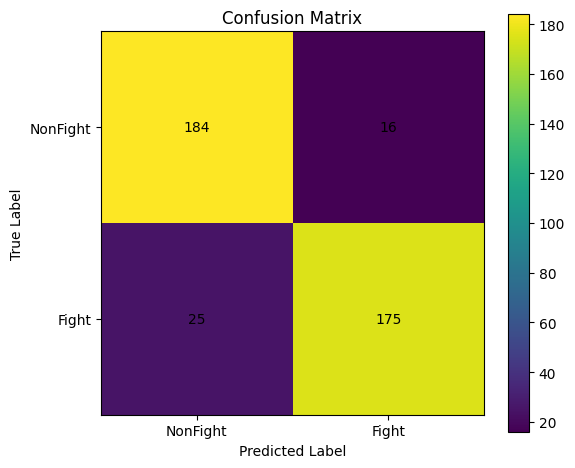

In [56]:
# Confusion Matrix
cm = confusion_matrix(test_labels,test_predictions)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks([0, 1], ["NonFight", "Fight"])
plt.yticks([0, 1], ["NonFight", "Fight"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

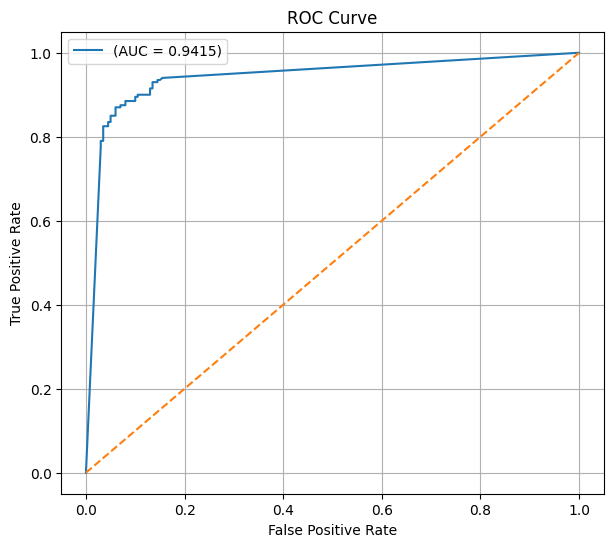

In [57]:
# ROC Curve

fpr, tpr, thresholds = roc_curve(test_labels, test_probabilities)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"(AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

### Save Final Model

In [58]:
torch.save(model_base.state_dict(), "r3d18_rwf2000_final.pth")
print("Model saved to r3d18_rwf2000_final.pth")

Model saved to r3d18_rwf2000_final.pth
